# Karnataka Electricity Demand Forecast

In this project I tried to predict the daily electricity demand of Karnataka.

Questions:
- How has demand changed over the years?
- Which months use the most electricity?
- Can a simple model predict tomorrow's demand better than just using today's value?

Data:
- Daily electricity demand of Karnataka from 2013 to April 2024 (Grid-India daily reports, taken from a public CSV file). Unit is MU (million units).
- Daily maximum temperature of Bengaluru from the Open-Meteo weather website.

I used Python (pandas, scikit-learn) and SQL.

## Loading and cleaning the data

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

demand = pd.read_csv("daily_energy_met_MU.csv", usecols=["Date", "Karnataka"])
demand.columns = ["date", "demand"]
demand["date"] = pd.to_datetime(demand["date"])

print(demand.shape)
print("missing values:", demand["demand"].isnull().sum())
print("duplicate dates:", demand["date"].duplicated().sum())

(3955, 2)
missing values: 0
duplicate dates: 55


In [2]:
# keep one row for each date
demand = demand.drop_duplicates(subset="date")

# the weather data starts from April 2013, so I start from there
demand = demand[demand["date"] >= "2013-04-01"]

weather = pd.read_csv("bengaluru_weather.csv", parse_dates=["date"])
data = demand.merge(weather[["date", "temp_max_c"]], on="date")

print(data.shape)
data.head()

(3892, 3)


,date,demand,temp_max_c
0,2013-04-01,159.4,32.1
1,2013-04-02,164.6,31.8
2,2013-04-03,163.7,31.8
3,2013-04-04,161.8,33.4
4,2013-04-05,163.3,33.2


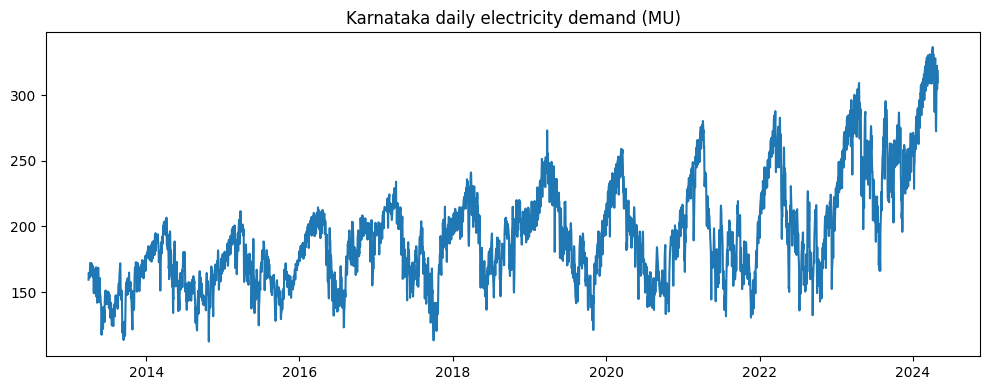

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(data["date"], data["demand"])
plt.title("Karnataka daily electricity demand (MU)")
plt.tight_layout()
plt.savefig("demand_over_time.png")
plt.show()

Demand is going up over the years, with a big jump in 2023 and 2024.

## Analysis with SQL

In [4]:
data["date"] = data["date"].dt.strftime("%Y-%m-%d")
conn = sqlite3.connect(":memory:")
data.to_sql("daily", conn, index=False)

3892

### Average demand per year

In [5]:
pd.read_sql("""
SELECT strftime('%Y', date) AS year,
       ROUND(AVG(demand), 1) AS avg_demand
FROM daily
GROUP BY year
""", conn)

,year,avg_demand
0,2013,151.6
1,2014,165.3
2,2015,167.9
3,2016,183.5
4,2017,181.9
5,2018,195.4
6,2019,196.5
7,2020,194.7
8,2021,196.6
9,2022,207.3


Average daily demand went from 165 MU in 2014 to 251 MU in 2023.

### Average demand by month

In [6]:
by_month = pd.read_sql("""
SELECT CAST(strftime('%m', date) AS INT) AS month,
       ROUND(AVG(demand), 1) AS avg_demand,
       ROUND(AVG(temp_max_c), 1) AS avg_temp
FROM daily
GROUP BY month
""", conn)

by_month

,month,avg_demand,avg_temp
0,1,211.4,27.4
1,2,229.8,29.8
2,3,240.8,32.5
3,4,224.4,33.7
4,5,187.6,31.5
5,6,175.3,28.0
6,7,168.2,26.8
7,8,175.7,26.8
8,9,174.1,26.9
9,10,171.2,27.2


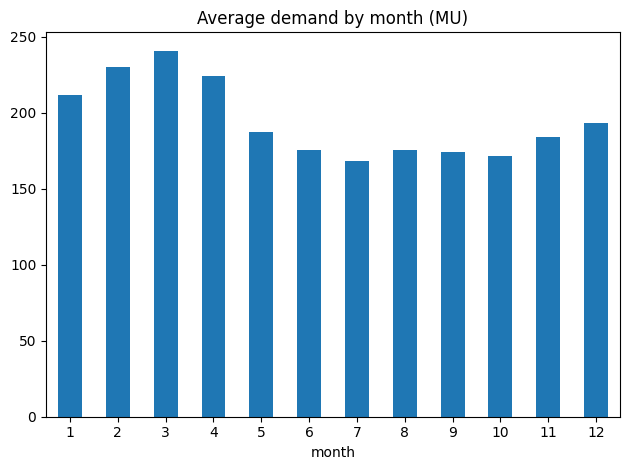

In [7]:
by_month.plot(x="month", y="avg_demand", kind="bar", legend=False, title="Average demand by month (MU)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("demand_by_month.png")
plt.show()

Demand is highest in February, March and April. These are hot months before the monsoon, and farmers also use more pumps for irrigation. Demand is lowest in July.

### Average demand by day of the week

In [8]:
pd.read_sql("""
SELECT CASE strftime('%w', date)
           WHEN '0' THEN 'Sunday' WHEN '1' THEN 'Monday' WHEN '2' THEN 'Tuesday'
           WHEN '3' THEN 'Wednesday' WHEN '4' THEN 'Thursday' WHEN '5' THEN 'Friday'
           ELSE 'Saturday'
       END AS day,
       ROUND(AVG(demand), 1) AS avg_demand
FROM daily
GROUP BY day
ORDER BY avg_demand DESC
""", conn)

,day,avg_demand
0,Friday,198.0
1,Wednesday,197.5
2,Thursday,197.4
3,Tuesday,196.9
4,Saturday,195.0
5,Monday,194.3
6,Sunday,183.8


Sunday has the lowest demand, because offices and factories are closed.

## Forecasting

Inputs I used to predict a day's demand:
- yesterday's demand
- demand on the same day last week
- maximum temperature
- is it a Sunday (demand drops)
- is it a Monday (demand goes back up)

I trained the model on all data except the last 12 weeks, and tested it on the last 12 weeks. I did not shuffle the data, because the model should learn from the past and predict the future.

To check the model I compare it with a simple guess: "today's demand = yesterday's demand".

The error is measured with MAPE, which is the average percentage error.

In [9]:
data["date"] = pd.to_datetime(data["date"])

# add the missing calendar days so that shift(1) really gives yesterday
data = data.set_index("date").asfreq("D")

data["yesterday"] = data["demand"].shift(1)
data["last_week"] = data["demand"].shift(7)
data["is_sunday"] = (data.index.dayofweek == 6).astype(int)
data["is_monday"] = (data.index.dayofweek == 0).astype(int)
data = data.dropna()

inputs = ["yesterday", "last_week", "temp_max_c", "is_sunday", "is_monday"]

split_date = data.index.max() - pd.Timedelta(weeks=12)
train = data[data.index <= split_date]
test = data[data.index > split_date]
print("train days:", len(train), " test days:", len(test))

train days: 3592  test days: 84


In [10]:
model = LinearRegression()
model.fit(train[inputs], train["demand"])
prediction = model.predict(test[inputs])

def mape(actual, predicted):
    return (abs(actual - predicted) / actual).mean() * 100

print("Simple guess (yesterday) error:", round(mape(test["demand"], test["yesterday"]), 2), "%")
print("Linear regression error:       ", round(mape(test["demand"], prediction), 2), "%")

Simple guess (yesterday) error: 2.7 %
Linear regression error:        1.79 %


In [11]:
pd.Series(model.coef_, index=inputs).round(2)

yesterday      0.94
last_week      0.04
temp_max_c     0.31
is_sunday    -10.98
is_monday     10.10
dtype: float64

How to read this:
- Yesterday's demand is the most important input. Each 1 MU more yesterday means about 0.94 MU more today.
- On Sundays the model predicts about 11 MU less, and on Mondays about 10 MU more.
- Each extra degree of temperature adds about 0.3 MU.

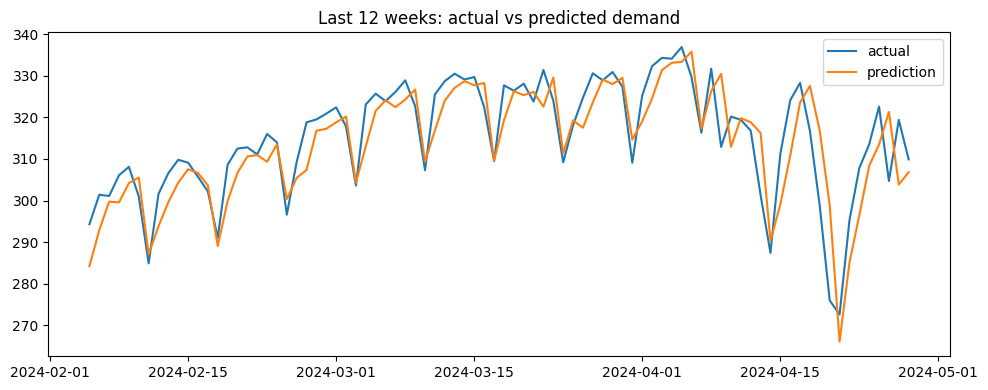

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(test.index, test["demand"], label="actual")
plt.plot(test.index, prediction, label="prediction")
plt.title("Last 12 weeks: actual vs predicted demand")
plt.legend()
plt.tight_layout()
plt.savefig("forecast.png")
plt.show()

## Conclusion

- Electricity demand in Karnataka is growing every year.
- Demand is highest in February to April and lowest in July.
- Sunday has the lowest demand.
- The linear regression model has an average error of 1.79%. The simple guess has 2.70%. So the model is about 34% better.

Limitations:
- I used the actual temperature of the day. In real life we would only have a weather forecast, so the real error would be a bit higher.
- I used Bengaluru temperature for the whole state.
- The data ends in April 2024.